<a href="https://colab.research.google.com/github/Safuraali/sem_7/blob/main/WEEK10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Animal Data with Clusters:
   Weight_kg  Height_cm  Cluster
0   5.496714  19.308678        2
1   5.647689  27.615149        2
2   4.765847  18.829315        2
3   6.579213  23.837174        2
4   4.530526  22.712800        2


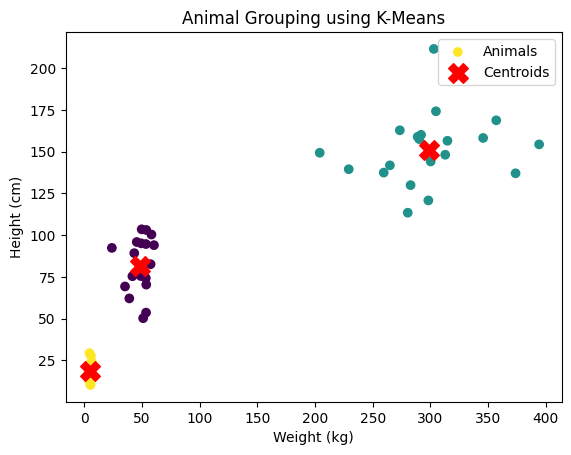

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
# Create animal data
np.random.seed(42)
small = np.random.normal(loc=[5, 20], scale=[1, 5], size=(20, 2))
medium = np.random.normal(loc=[50, 80], scale=[10, 15], size=(20, 2))
large = np.random.normal(loc=[300, 150], scale=[50, 25], size=(20, 2))
X_animals = pd.DataFrame(np.vstack([small, medium, large]), columns=['Weight_kg', 'Height_cm'])
# Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_animals)
# Apply K-Means
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
X_animals['Cluster'] = kmeans.fit_predict(X_scaled)
# Get centroids in original units
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
# Display data
print("Animal Data with Clusters:")
print(X_animals.head())
# Plot clusters
plt.scatter(X_animals['Weight_kg'], X_animals['Height_cm'],c=X_animals['Cluster'], cmap='viridis', label='Animals')
# Plot centroids
plt.scatter(centroids[:, 0], centroids[:, 1],color='red', marker='X', s=200, label='Centroids')
plt.xlabel("Weight (kg)")
plt.ylabel("Height (cm)")
plt.title("Animal Grouping using K-Means")
plt.legend()
plt.show()

Student Data:
   Study_Hours_Week  Sleep_Hours_Night
0                33                5.0
1                19                6.0
2                12                8.6
3                25                7.6
4                23                5.6

Student Groups:
   Study_Hours_Week  Sleep_Hours_Night  Cluster
0                33                5.0        0
1                19                6.0        0
2                12                8.6        1
3                25                7.6        0
4                23                5.6        0


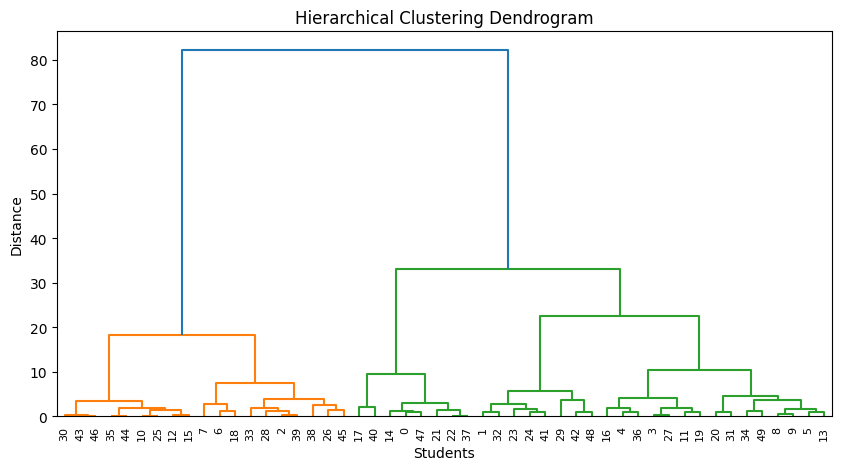

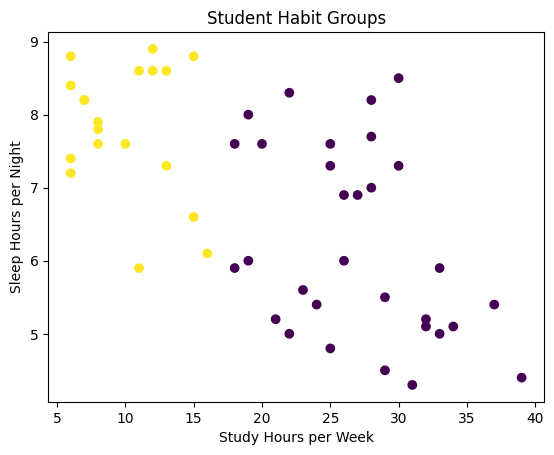

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
np.random.seed(42)
X_students = pd.DataFrame({'Study_Hours_Week': np.random.randint(5, 40, 50),'Sleep_Hours_Night': np.random.uniform(4, 9, 50).round(1)})
# Add patterns
X_students.loc[X_students['Study_Hours_Week'] > 30,'Sleep_Hours_Night'] = np.random.uniform(4, 6,sum(X_students['Study_Hours_Week'] > 30)).round(1)
X_students.loc[X_students['Study_Hours_Week'] < 10,'Sleep_Hours_Night'] = np.random.uniform(7, 9, sum(X_students['Study_Hours_Week'] < 10)).round(1)
print("Student Data:")
print(X_students.head())
# Hierarchical clustering
Z = linkage(X_students, method='ward')
# Create 2 clusters
model = AgglomerativeClustering(n_clusters=2)
X_students['Cluster'] = model.fit_predict(X_students)
print("\nStudent Groups:")
print(X_students.head())
# Plot dendrogram
plt.figure(figsize=(10, 5))
dendrogram(Z)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Students")
plt.ylabel("Distance")
plt.show()
# Scatter plot
plt.scatter(X_students['Study_Hours_Week'],X_students['Sleep_Hours_Night'],c=X_students['Cluster'], cmap='viridis')
plt.xlabel("Study Hours per Week")
plt.ylabel("Sleep Hours per Night")
plt.title("Student Habit Groups")
plt.show()